In [1]:
# First we need to import all of the packages we will be using!
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

In [2]:
# First model: no synthesis and degradation
# This is the definition of our system of ODEs for the model
def first_model(states,t):
    # Our "states" list has the state variables in the following order:
    # S, KS, Sstar, PSstar, K, P
    S = states[0]
    KS = states[1]
    Sstar = states[2]
    PSstar = states[3]
    K = states[4]
    P = states[5]
    # The above just makes it easier to relate our ODEs to the ones in the Homework text
    S_prime = -k_plus*S*K + k_minus*KS + k_cat*PSstar
    KS_prime = k_plus*S*K - k_minus*KS - k_cat*KS
    Sstar_prime = -k_plus*Sstar*P + k_minus*PSstar + k_cat*KS
    PSstar_prime = k_plus*Sstar*P - k_minus*PSstar - k_cat*PSstar
    K_prime = -k_plus*S*K + k_minus*KS + k_cat*KS
    P_prime = -k_plus*Sstar*P + k_minus*PSstar + k_cat*PSstar
    states_prime = [S_prime,KS_prime,Sstar_prime,PSstar_prime,K_prime,P_prime]
    return states_prime
# This is where we will define the parameters that we won't change for our model
k_cat = 9.9
k_minus = 0.1
k_plus = 1


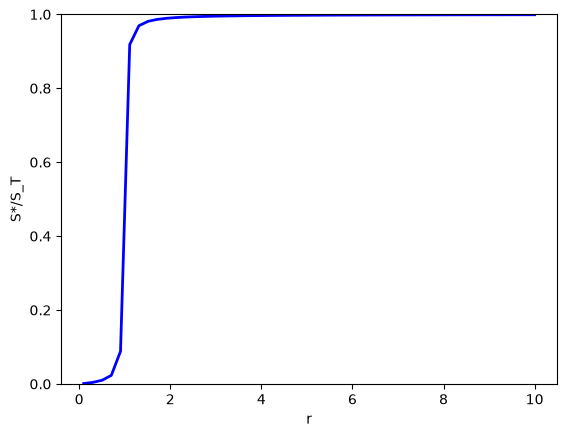

In [4]:
# STEADY-STATE responses of the first model
# (hint: you will need to run this TWICE, once for unsaturated, once for saturated)

# First, define our initial conditions
# We will be varying the value of K_0

S_0 = 1000 # This is the variable you change to change saturation!
KS_0 = 0.0
Sstar_0 = 0.0
PSstar_0 = 0.0
P_0 = 0.001

# Here, we define our list of K values:
K_values = np.linspace(0.0001, 0.01)

#These will be the lists that hold the results
Sstar_results = []
r_values = []

for K_0 in K_values:
    # First, we create our initial conditions
    # We do this inside the for loop because K_0 is changing
    states_0 = [S_0,KS_0,Sstar_0,PSstar_0,K_0,P_0]
    # To intgrate ODEs, we need a "t" vector for time
    # Note that the units on "t" are in seconds
    # We choose a very long maximum time (20,000,000 seconds!) to insure we reach steady-state
    t = np.linspace(0,20000000,2000)
    # Now, integrate the ODEs and put the results in "solution"
    solution = odeint(first_model,states_0,t)
    # Next, we caluclate the effective "r" value and put it in the vector for r
    r = k_cat*K_0 / (k_cat*P_0)
    r_values.append(r)
    # Now, calculate our output, which remember from lecture is S*/S_t
    # (the concentration of modified substrate divided by the total substrate concentration)
    # Note that, since total substrate is conserved, S_T is just equal to S_0
    # Note that we are taking the last time point. Since there are 2,000 time points
    # The index of the last time point is 1,999
    norm_S = solution[1999,2]/S_0
    # Append this result to the vector of our results
    Sstar_results.append(norm_S)
plt.plot(r_values,Sstar_results,'b-',linewidth=2)
plt.xlabel('r')
plt.ylabel('S*/S_T')
plt.ylim((0,1.0))
plt.show()

In [5]:
# Second model: includes synthesis and degradation
# This is the definition of our system of ODEs for the model
def second_model(states,t):
    # Our "states" list has the state variables in the following order:
    # S, KS, Sstar, PSstar, K, P
    S = states[0]
    KS = states[1]
    Sstar = states[2]
    PSstar = states[3]
    K = states[4]
    P = states[5]
    # PUT YOUR ODES below!!!
    S_prime = -k_plus*S*K + k_minus*KS + k_cat*PSstar + Q - delta*S
    KS_prime = k_plus*S*K - k_minus*KS - k_cat*KS - delta*KS
    Sstar_prime = -k_plus*Sstar*P + k_minus*PSstar + k_cat*KS - delta*Sstar
    PSstar_prime = k_plus*Sstar*P - k_minus*PSstar - k_cat*PSstar - delta*PSstar
    K_prime = -k_plus*S*K + k_minus*KS + k_cat*KS + delta*KS
    P_prime = -k_plus*Sstar*P + k_minus*PSstar + k_cat*PSstar + delta*PSstar
    # Hint: copy the ODEs from first_model and modify them to include synthesis and degradation

    # your ODEs go above!
    states_prime = [S_prime,KS_prime,Sstar_prime,PSstar_prime,K_prime,P_prime]
    return states_prime

k_cat = 9.9
k_minus = 0.1
k_plus = 1
delta = 2e-5

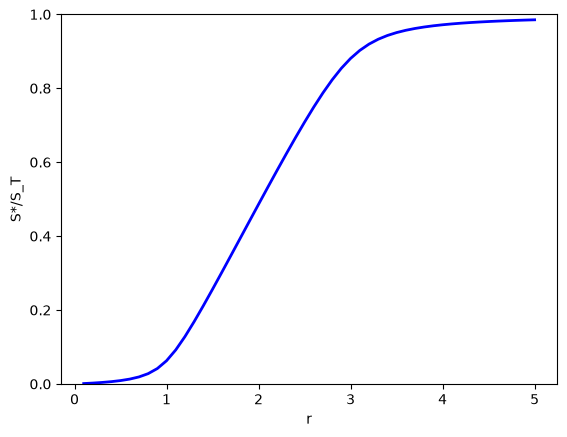

In [7]:
# STEADY-STATE responses of the second model
# (hint: you will need to run this TWICE, once for unsaturated, once for saturated)

# First, define our initial conditions
S_0 = 1000 # This is the variable you change to change saturation!
KS_0 = 0.0
Sstar_0 = 0.0
PSstar_0 = 0.0
P_0 = 0.001

Q = delta*S_0 # This line handily calculates the value of 'Q' that we need

#PARAMETERS
# This is where we  define the parameters that we won't change for our second model
# This is the same as we had above for our first model
K_values = np.linspace(0.0001, 0.005)
Sstar_results = []
r_values = []
for K_0 in K_values:
    states_0 = [S_0,KS_0,Sstar_0,PSstar_0,K_0,P_0]
    t = np.linspace(0,2000000,2000)
    solution = odeint(second_model,states_0,t)
    r = k_cat*K_0 / (k_cat*P_0)
    r_values.append(r)
    Sstar_results.append(solution[1999,2]/S_0)
# PLOT your steady-state results
# Run this once for unsaturated, then change the block above and make a graph for saturated
plt.plot(r_values,Sstar_results,'b-',linewidth=2)
plt.xlabel('r')
plt.ylabel('S*/S_T')
plt.ylim((0,1))
plt.show()

**Part 2: Kinase Cascades**


In [12]:
# 3 layer model
# This is the definition of our system of ODEs for the model
def three_layer_model(states,t):
    # Our "states" list has the state variables in the following order:
    # K2, K2star, K3, K3star, K4, K4star
    K2 = states[0]
    K2star = states[1]
    K3 = states[2]
    K3star = states[3]
    K4 = states[4]
    K4star = states[5]
    # The above just makes it easier to relate our ODEs to the ones in the Homework text
    K2_prime = -k_a*K1star*K2 + k_u*K2star
    K2star_prime = k_a*K1star*K2 - k_u*K2star
    K3_prime = -k_a*K2star*K3 + k_u*K3star
    K3star_prime = k_a*K2star*K3 - k_u*K3star
    K4_prime = -k_a*K3star*K4 + k_u*K4star
    K4star_prime = k_a*K3star*K4 - k_u*K4star
    states_prime = [K2_prime,K2star_prime,K3_prime,K3star_prime,K4_prime,K4star_prime]
    return states_prime

In [13]:
# 4 layer model
# This is the definition of our system of ODEs for the model
def four_layer_model(states,t):
    # Our "states" list has the state variables in the following order:
    # K2, K2star, K3, K3star, K4, K4star, K5, K5star
    K2 = states[0]
    K2star = states[1]
    K3 = states[2]
    K3star = states[3]
    K4 = states[4]
    K4star = states[5]
    K5 = states[6]
    K5star = states[7]
    # The change equations here are the same as above for the three layer model
    K2_prime = -k_a*K1star*K2 + k_u*K2star
    K2star_prime = k_a*K1star*K2 - k_u*K2star
    K3_prime = -k_a*K2star*K3 + k_u*K3star
    K3star_prime = k_a*K2star*K3 - k_u*K3star
    K4_prime = -k_a*K3star*K4 + k_u*K4star
    K4star_prime = k_a*K3star*K4 - k_u*K4star

    # Below, ADD the additional change equations you found to complete the four layer model
    ###
    K5_prime = -k_a*K4star*K5 + k_u*K5star
    K5star_prime = k_a*K4star*K5 - k_u*K5star
    ###

    states_prime = [K2_prime,K2star_prime,K3_prime,K3star_prime,K4_prime,K4star_prime,K5_prime,K5star_prime]
    return states_prime

In [14]:
# 5 layer model
# This is the definition of our system of ODEs for the model
def five_layer_model(states,t):
    # Our "states" list has the state variables in the following order:
    # K2, K2star, K3, K3star, K4, K4star, K5, K5star, K6, K6star
    K2 = states[0]
    K2star = states[1]
    K3 = states[2]
    K3star = states[3]
    K4 = states[4]
    K4star = states[5]
    K5 = states[6]
    K5star = states[7]
    K6 = states[8]
    K6star = states[9]
    # The change equations here are the same as above for the three layer model
    K2_prime = -k_a*K1star*K2 + k_u*K2star
    K2star_prime = k_a*K1star*K2 - k_u*K2star
    K3_prime = -k_a*K2star*K3 + k_u*K3star
    K3star_prime = k_a*K2star*K3 - k_u*K3star
    K4_prime = -k_a*K3star*K4 + k_u*K4star
    K4star_prime = k_a*K3star*K4 - k_u*K4star

    # Below, ADD the additional change equations you found to complete the five layer model
    #(note you will need to include the additions you made for the four layer model as well here)
    ###
    K5_prime = -k_a*K4star*K5 + k_u*K5star
    K5star_prime = k_a*K4star*K5 - k_u*K5star
    K6_prime = -k_a*K5star*K6 + k_u*K6star
    K6star_prime = k_a*K5star*K6 - k_u*K6star
    ###

    states_prime = [K2_prime,K2star_prime,K3_prime,K3star_prime,K4_prime,K4star_prime,K5_prime,K5star_prime,K6_prime,K6star_prime]
    return states_prime

In [15]:
# PARAMETERS
# This is where we will define the parameters that we won't change for our model
k_a = 1
k_u = 0.1

In [16]:
# STEADY-STATE responses

# First, define our initial conditions
# These are going to be the same for values of 'K1star'
K2 = 0.1
K2star = 0.0
K3 = 0.2
K3star = 0.0
K4 = 0.4
K4star = 0.0
K5 = 0.8
K5star = 0.0
K6 = 1.6
K6star = 0.0

# Here, we define our list of K1star values:
K1star_values = np.linspace(0, 0.1)

#This will be an array that hold the steady state results
ss_results = np.empty((3,0))

for K1star in K1star_values:
    # To intgrate ODEs, we need a "t" vector for time
    t = np.linspace(0,1000,1000)
    # We create our initial conditions for the three-layer model
    states_0 = [K2,K2star,K3,K3star,K4,K4star]
    # Now, integrate the three-layer model ODEs and put the results in "solution_3"
    solution_3 = odeint(three_layer_model,states_0,t)
    # We create our initial conditions for the four-layer model
    states_0 = [K2,K2star,K3,K3star,K4,K4star,K5,K5star]
    # Now, integrate the four-layer model ODEs and put the results in "solution_4"
    solution_4 = odeint(four_layer_model,states_0,t)
    # We create our initial conditions for the five-layer model
    states_0 = [K2,K2star,K3,K3star,K4,K4star,K5,K5star,K6, K6star]
    # Now, integrate the five-layer model ODEs and put the results in "solution_5"
    solution_5 = odeint(five_layer_model,states_0,t)
    ss_output= np.array([[solution_3[999,5]/K4], [solution_4[999,7]/K5], [solution_5[999,9]/K6]])
    # Append this result to the array of our results
    ss_results = np.append(ss_results, ss_output, axis=1)

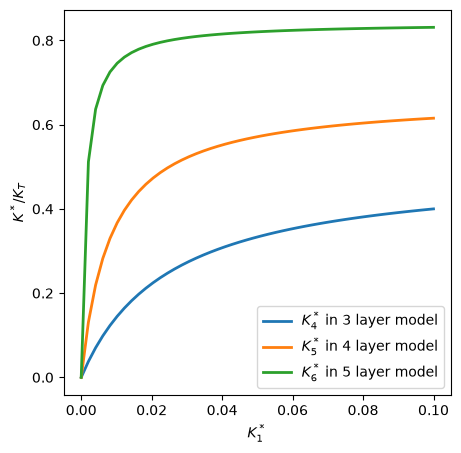

In [17]:
#PLOT your steady-state results
# You can save this as a JPG or PNG and insert it into your HW answer (you can google how to do that!)
# Or you can just take a screenshot. Be warned, however, the figure needs to be big enough for us to see!
plt.figure(figsize=(5, 5))
plt.plot(K1star_values,ss_results[0, :],linewidth=2, label='$K_4^*$ in 3 layer model')
plt.plot(K1star_values,ss_results[1, :],linewidth=2, label='$K_5^*$ in 4 layer model')
plt.plot(K1star_values,ss_results[2, :],linewidth=2, label='$K_6^*$ in 5 layer model')
plt.xlabel('$K_1^*$')
plt.ylabel('$K^*/K_T$')
plt.legend()
plt.show()


In [22]:
# DYNAMICS: 3 layer model with finite signal


# First, define our initial conditions
K1star = 0.05
K2 = 0.1
K2star = 0.0
K3 = 0.2
K3star = 0.0
K4 = 0.4
K4star = 0.0

states_0 = [K2,K2star,K3,K3star,K4,K4star]

# Now we define a new variable for "time" so we can see the dynamics
t = np.linspace(0,100,1000)

# This is the definition of our system of ODEs for the three leyer model
# now with the option to turn off the activating signal
def three_layer_model_finite_signal(states,t):
    # Our "states" list has the state variables in the following order:
    # K2, K2star, K3, K3star, K4, K4star
    K2 = states[0]
    K2star = states[1]
    K3 = states[2]
    K3star = states[3]
    K4 = states[4]
    K4star = states[5]
    # The above just makes it easier to relate our ODEs to the ones in the Homework text
    # We add the following lines to turn off the activating signal, K1star, after the time "end_signal"
    if t<end_signal:
        K1star = 0.05
    else:
        K1star = 0
    #The rest of the model remains the same:
    K2_prime = -k_a*K1star*K2 + k_u*K2star
    K2star_prime = k_a*K1star*K2 - k_u*K2star
    K3_prime = -k_a*K2star*K3 + k_u*K3star
    K3star_prime = k_a*K2star*K3 - k_u*K3star
    K4_prime = -k_a*K3star*K4 + k_u*K4star
    K4star_prime = k_a*K3star*K4 - k_u*K4star
    states_prime = [K2_prime,K2star_prime,K3_prime,K3star_prime,K4_prime,K4star_prime]
    return states_prime

#ENTER a time for the signal to turn off (value should be in the range of time variable, t)
###
end_signal = 10
###

solution_finite = odeint(three_layer_model_finite_signal,states_0,t)

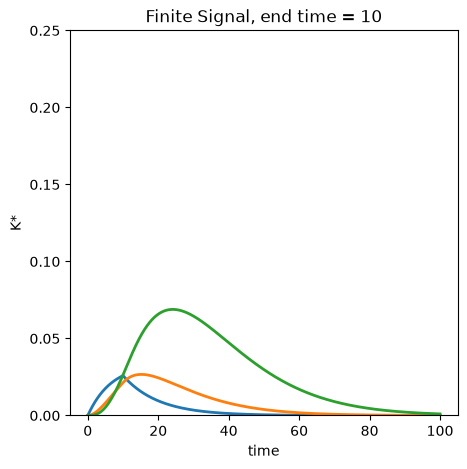

In [23]:
# PLOT dynamics of kinase activation with finite signal
plt.figure(1, figsize=(5, 5))
plt.plot(t,solution_finite[:,1],linewidth=2, label = "K2*")
plt.plot(t,solution_finite[:,3],linewidth=2, label = "K3*")
plt.plot(t,solution_finite[:,5],linewidth=2, label = "K4*")
plt.xlabel('time')
plt.ylabel('K*')
plt.ylim((0,0.25))
plt.title("Finite Signal, end time = " + str(end_signal))
plt.show()